In [2]:
import pandas as pd

df = pd.read_csv("phishing_site_urls.csv")
print(df.shape)
print(df["Label"].value_counts())
print(df.head())

(549346, 2)
Label
good    392924
bad     156422
Name: count, dtype: int64
                                                 URL Label
0  nobell.it/70ffb52d079109dca5664cce6f317373782/...   bad
1  www.dghjdgf.com/paypal.co.uk/cycgi-bin/webscrc...   bad
2  serviciosbys.com/paypal.cgi.bin.get-into.herf....   bad
3  mail.printakid.com/www.online.americanexpress....   bad
4  thewhiskeydregs.com/wp-content/themes/widescre...   bad


In [3]:
# 1. Remover duplicatas (evita a mesma URL no treino e no teste)
antes = len(df)
df = df.drop_duplicates(subset="URL").reset_index(drop=True)
print(f"Linhas antes: {antes} | depois: {len(df)}")

# 2. Transformar o rótulo em número: bad (phishing) = 1, good = 0
df["y"] = (df["Label"] == "bad").astype(int)

# 3. Conferir
print(df["y"].value_counts(normalize=True))
df.head()

Linhas antes: 549346 | depois: 507195
y
0    0.774647
1    0.225353
Name: proportion, dtype: float64


,URL,Label,y
0,nobell.it/70ffb52d079109dca5664cce6f317373782/...,bad,1
1,www.dghjdgf.com/paypal.co.uk/cycgi-bin/webscrc...,bad,1
2,serviciosbys.com/paypal.cgi.bin.get-into.herf....,bad,1
3,mail.printakid.com/www.online.americanexpress....,bad,1
4,thewhiskeydregs.com/wp-content/themes/widescre...,bad,1


In [4]:
import re, math
from urllib.parse import urlparse
from collections import Counter

PALAVRAS = ["login", "verify", "secure", "account", "update",
            "confirm", "signin", "bank", "paypal", "webscr", "ebay"]

def entropia(s):
    if not s:
        return 0
    c = Counter(s)
    return -sum((n / len(s)) * math.log2(n / len(s)) for n in c.values())

def extrair(url):
    try:
        p = urlparse("http://" + url)
        dominio, caminho = p.netloc, p.path
    except ValueError:  # algumas URLs são malformadas
        dominio, caminho = url.split("/")[0], ""
    u = url.lower()
    return {
        "len_url": len(url),
        "len_dominio": len(dominio),
        "len_caminho": len(caminho),
        "n_pontos": url.count("."),
        "n_hifens": url.count("-"),
        "n_barras": url.count("/"),
        "n_digitos": sum(ch.isdigit() for ch in url),
        "n_arroba": url.count("@"),
        "n_interrog": url.count("?"),
        "n_igual": url.count("="),
        "n_percent": url.count("%"),
        "n_subdominios": max(dominio.count(".") - 1, 0),
        "dominio_e_ip": int(bool(re.fullmatch(r"\d{1,3}(\.\d{1,3}){3}(:\d+)?", dominio))),
        "n_palavras_suspeitas": sum(w in u for w in PALAVRAS),
        "termina_php": int(caminho.lower().endswith(".php")),
        "termina_html": int(caminho.lower().endswith((".htm", ".html"))),
        "entropia": entropia(url),
    }

X = pd.DataFrame(df["URL"].apply(extrair).tolist())
y = df["y"]
print(X.shape)
X.head()

(507195, 17)


,len_url,len_dominio,len_caminho,n_pontos,n_hifens,n_barras,n_digitos,n_arroba,n_interrog,n_igual,n_percent,n_subdominios,dominio_e_ip,n_palavras_suspeitas,termina_php,termina_html,entropia
0,225,9,125,6,4,10,58,0,1,4,0,0,0,1,1,0,5.026886
1,81,15,66,5,2,4,1,0,0,2,0,1,0,2,1,0,4.686883
2,177,16,161,7,1,11,47,0,0,0,0,0,0,3,0,0,4.721044
3,60,18,42,6,0,2,0,0,0,0,0,1,0,0,0,1,4.079842
4,116,19,60,1,1,10,21,0,1,0,0,0,0,0,0,0,4.608653


Matplotlib is building the font cache; this may take a moment.


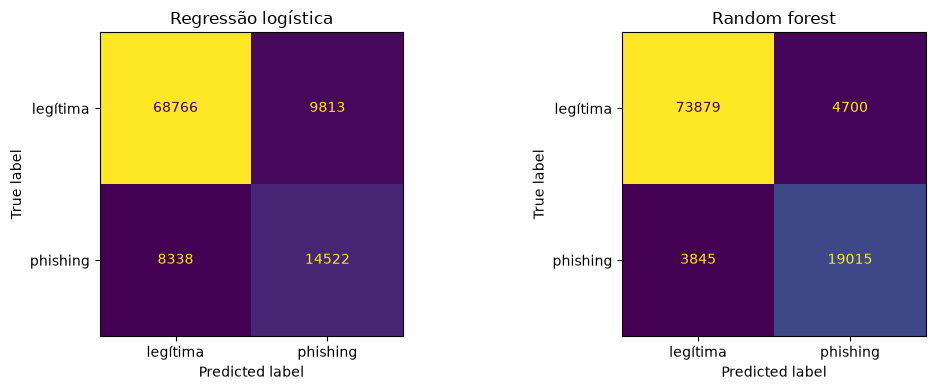

,modelo,precisão,recall,F1
0,Regressão logística,0.5968,0.6353,0.6154
1,Random forest,0.8018,0.8318,0.8165


In [5]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             ConfusionMatrixDisplay, classification_report)
import matplotlib.pyplot as plt

# 1. Separar treino (80%) e teste (20%), mantendo a proporção de phishing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 2. Os modelos
modelos = {
    "Regressão logística": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000, class_weight="balanced")
    ),
    "Random forest": RandomForestClassifier(
        n_estimators=100, class_weight="balanced", n_jobs=-1, random_state=42
    ),
}

# 3. Treinar e avaliar
resultados = []
fig, eixos = plt.subplots(1, len(modelos), figsize=(11, 4))

for ax, (nome, modelo) in zip(eixos, modelos.items()):
    modelo.fit(X_train, y_train)
    pred = modelo.predict(X_test)
    resultados.append({
        "modelo": nome,
        "precisão": precision_score(y_test, pred),
        "recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
    })
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, display_labels=["legítima", "phishing"], ax=ax, colorbar=False
    )
    ax.set_title(nome)

plt.tight_layout()
plt.show()
pd.DataFrame(resultados).round(4)